# Ingeniería de características
### Objetivo y alcance
La ingeniería de caracteristicas es una etapa crucial en el preprocesado.  Es util para limpiar y obtener caracterísitcas de entrada útiles en los modelos a desarrollar.


## Construcción
### Preparación del conjunto

Parte de la ingeniería de características conlleva a aprovechar el conocimiento que se tiene sobr ela aplicación y es que los objetos a detectar son proporcionales o asociados a una persona.  
Una primer aproximación lleva a generar datos de las cabezas para calcular dimensiones relativas de los objetos:

In [95]:
from pathlib import Path

import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


IMAGE_DIR = Path("../DataCapture/raw")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Ajustables: un píxel se considera "negro" si sus canales B, G y R
# están dentro de este rango.
BLACK_MAX = 40

# Filtros iniciales
MIN_WIDTH_PX = 20
MIN_HEIGHT_PX = 20
MIN_AREA_REL = 0.001
MAX_AREA_REL = 0.20
MIN_RECTANGULARITY = 0.60
MIN_ASPECT_RATIO = 0.35
MAX_ASPECT_RATIO = 2.00

rows = []

for image_path in sorted(IMAGE_DIR.iterdir()):
    if image_path.suffix.lower() not in EXTENSIONS:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    image_height, image_width = image.shape[:2]
    image_area = image_width * image_height

    # Máscara blanca para píxeles cercanos al negro.
    black_mask = cv2.inRange(
        image,
        (0, 0, 0),
        (BLACK_MAX, BLACK_MAX, BLACK_MAX)
    )

    # x, y, ancho, alto y área.
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        black_mask,
        connectivity=8
    )

    
    for label in range(1, num_labels):
        x, y, w, h, pixel_area = stats[label]

        area_rel = pixel_area / image_area
        aspect_ratio = w / h if h else 0
        rectangularity = pixel_area / (w * h) if w * h else 0

        if w < MIN_WIDTH_PX or h < MIN_HEIGHT_PX:
            continue
        if not MIN_AREA_REL <= area_rel <= MAX_AREA_REL:
            continue
        if not MIN_ASPECT_RATIO <= aspect_ratio <= MAX_ASPECT_RATIO:
            continue
        if rectangularity < MIN_RECTANGULARITY:
            continue

        rows.append({
            "imagen": image_path.name,
            "head_id": sum(r["imagen"] == image_path.name for r in rows) + 1,
            "x": int(x),
            "y": int(y),
            "w": int(w),
            "h": int(h),
            "centro_x": float(centroids[label][0]),
            "centro_y": float(centroids[label][1]),
            "area_relativa": area_rel,
            "aspect_ratio": aspect_ratio,
            "rectangularidad": rectangularity,
        })

head_df = pd.DataFrame(rows)

head_df.head()
head_df.to_csv("../DataCapture/mediciones_mascara_rostro.csv", index=False)


### Creación de variables nuevas y generación de características

In [96]:
IMAGE_DIR = Path("../DataCapture/raw")
CSV_PATH = Path("../DataCapture/anotaciones.csv")

annotations = pd.read_csv(CSV_PATH)
heads = pd.read_csv("../DataCapture/mediciones_mascara_rostro.csv")
heads = heads.groupby("imagen").agg({"x": "mean", "y": "mean", "w": "mean", "h": "mean"}).reset_index()

required = {"imagen", "x", "y", "w", "h"}
missing = required - set(annotations.columns)
if missing:
    raise ValueError(f"Faltan columnas en el CSV: {sorted(missing)}")

records = []

for row in annotations.itertuples(index=False):
    image_path = IMAGE_DIR / Path(row.imagen).name
    image = cv2.imread(str(image_path))
    head_data = heads[heads["imagen"] == row.imagen]

    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    image_height, image_width = image.shape[:2]
    head_height=np.mean(head_data["h"])
    head_width=np.mean(head_data["w"])
    x, y, w, h = map(float, (row.x, row.y, row.w, row.h))

    if w <= 0 or h <= 0:
        print(f"Caja inválida en {image_path.name}")
        continue

    records.append({
        "imagen": image_path.name,  # identificador; no predictor
        "x": x,
        "y": y,
        "w": w,
        "h": h,
        "image_width": image_width,
        "image_height": image_height,
        "center_x_norm": (x + w / 2) / image_width,
        "center_y_norm": (y + h / 2) / image_height,
        "box_width_rel": w / image_width,
        "box_width_rel_head": w / head_width,
        "box_height_rel": h / image_height,
        "box_height_rel_head": h / head_height,
        "box_area_rel": (w * h) / (image_width * image_height),
        "box_area_rel_head": (w * h) / (head_width * head_height),
        "box_aspect_ratio": w / h,
    })

features_df = pd.DataFrame(records)
features_df.head()

,imagen,x,y,w,h,image_width,image_height,center_x_norm,center_y_norm,box_width_rel,box_width_rel_head,box_height_rel,box_height_rel_head,box_area_rel,box_area_rel_head,box_aspect_ratio
0,captura_20261003_153016_534962.jpg,219.0,387.0,39.0,59.0,640,480,0.372656,0.867708,0.060937,0.229412,0.122917,0.225191,0.007490,0.051661,0.661017
1,captura_20261003_153021_540685.jpg,396.0,382.0,37.0,52.0,640,480,0.647656,0.850000,0.057813,0.350711,0.108333,0.383764,0.006263,0.134590,0.711538
2,captura_20261003_153051_624221.jpg,259.0,203.0,11.0,14.0,640,480,0.413281,0.437500,0.017188,0.105263,0.029167,0.155556,0.000501,0.016374,0.785714
3,captura_20261003_153056_648946.jpg,294.0,300.0,11.0,11.0,640,480,0.467969,0.636458,0.017188,0.045175,0.022917,0.057592,0.000394,0.002602,1.000000
4,captura_20261003_153101_657504.jpg,244.0,217.0,15.0,13.0,640,480,0.392969,0.465625,0.023438,0.064240,0.027083,0.058427,0.000635,0.003753,1.153846


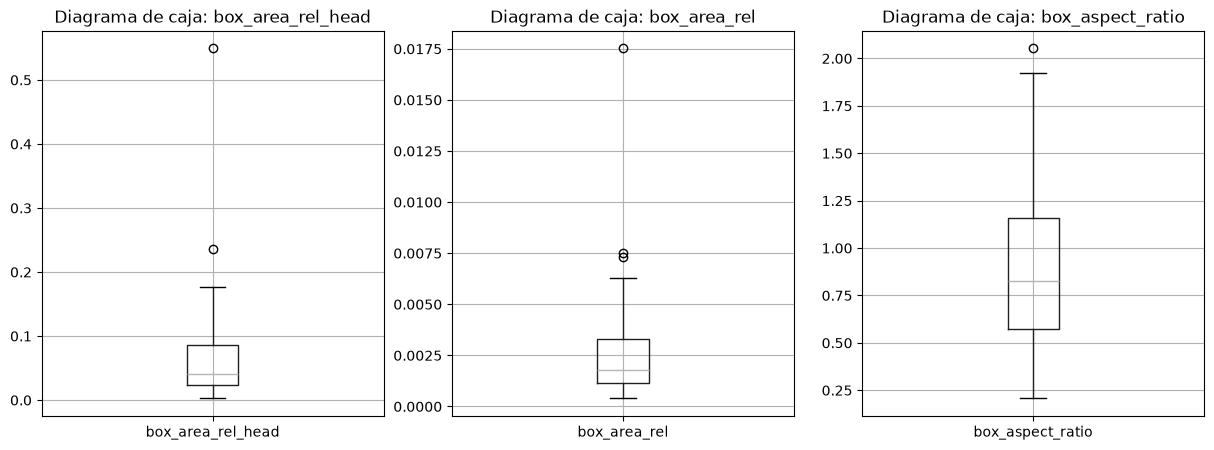

In [97]:
i=0
plt.figure(figsize=(15,5))
for col in ["box_area_rel_head","box_area_rel","box_aspect_ratio"]:
    i+=1
    #plt.figure(figsize=(5,5))
    plt.subplot(1, 3, i)
    features_df.boxplot(column=col)
    plt.title(f"Diagrama de caja: {col}")

Se observa que los objetos a encontrar respecto al tamaño de la cabena caen en escalas pequeñas y con sesgo hacia arriba, de igual manera el amontonamiento ocurre en escalas bajas.  En cuanto a la forma se observa una aproximación casi cuadrada abarcando varias geometrías.

## Normalización

### Distribuciones y binning

In [98]:
# Limpiamos valores nulos que se meten cuando hay imagenes sin objetos detectados
features_df = features_df.dropna().reset_index(drop=True)

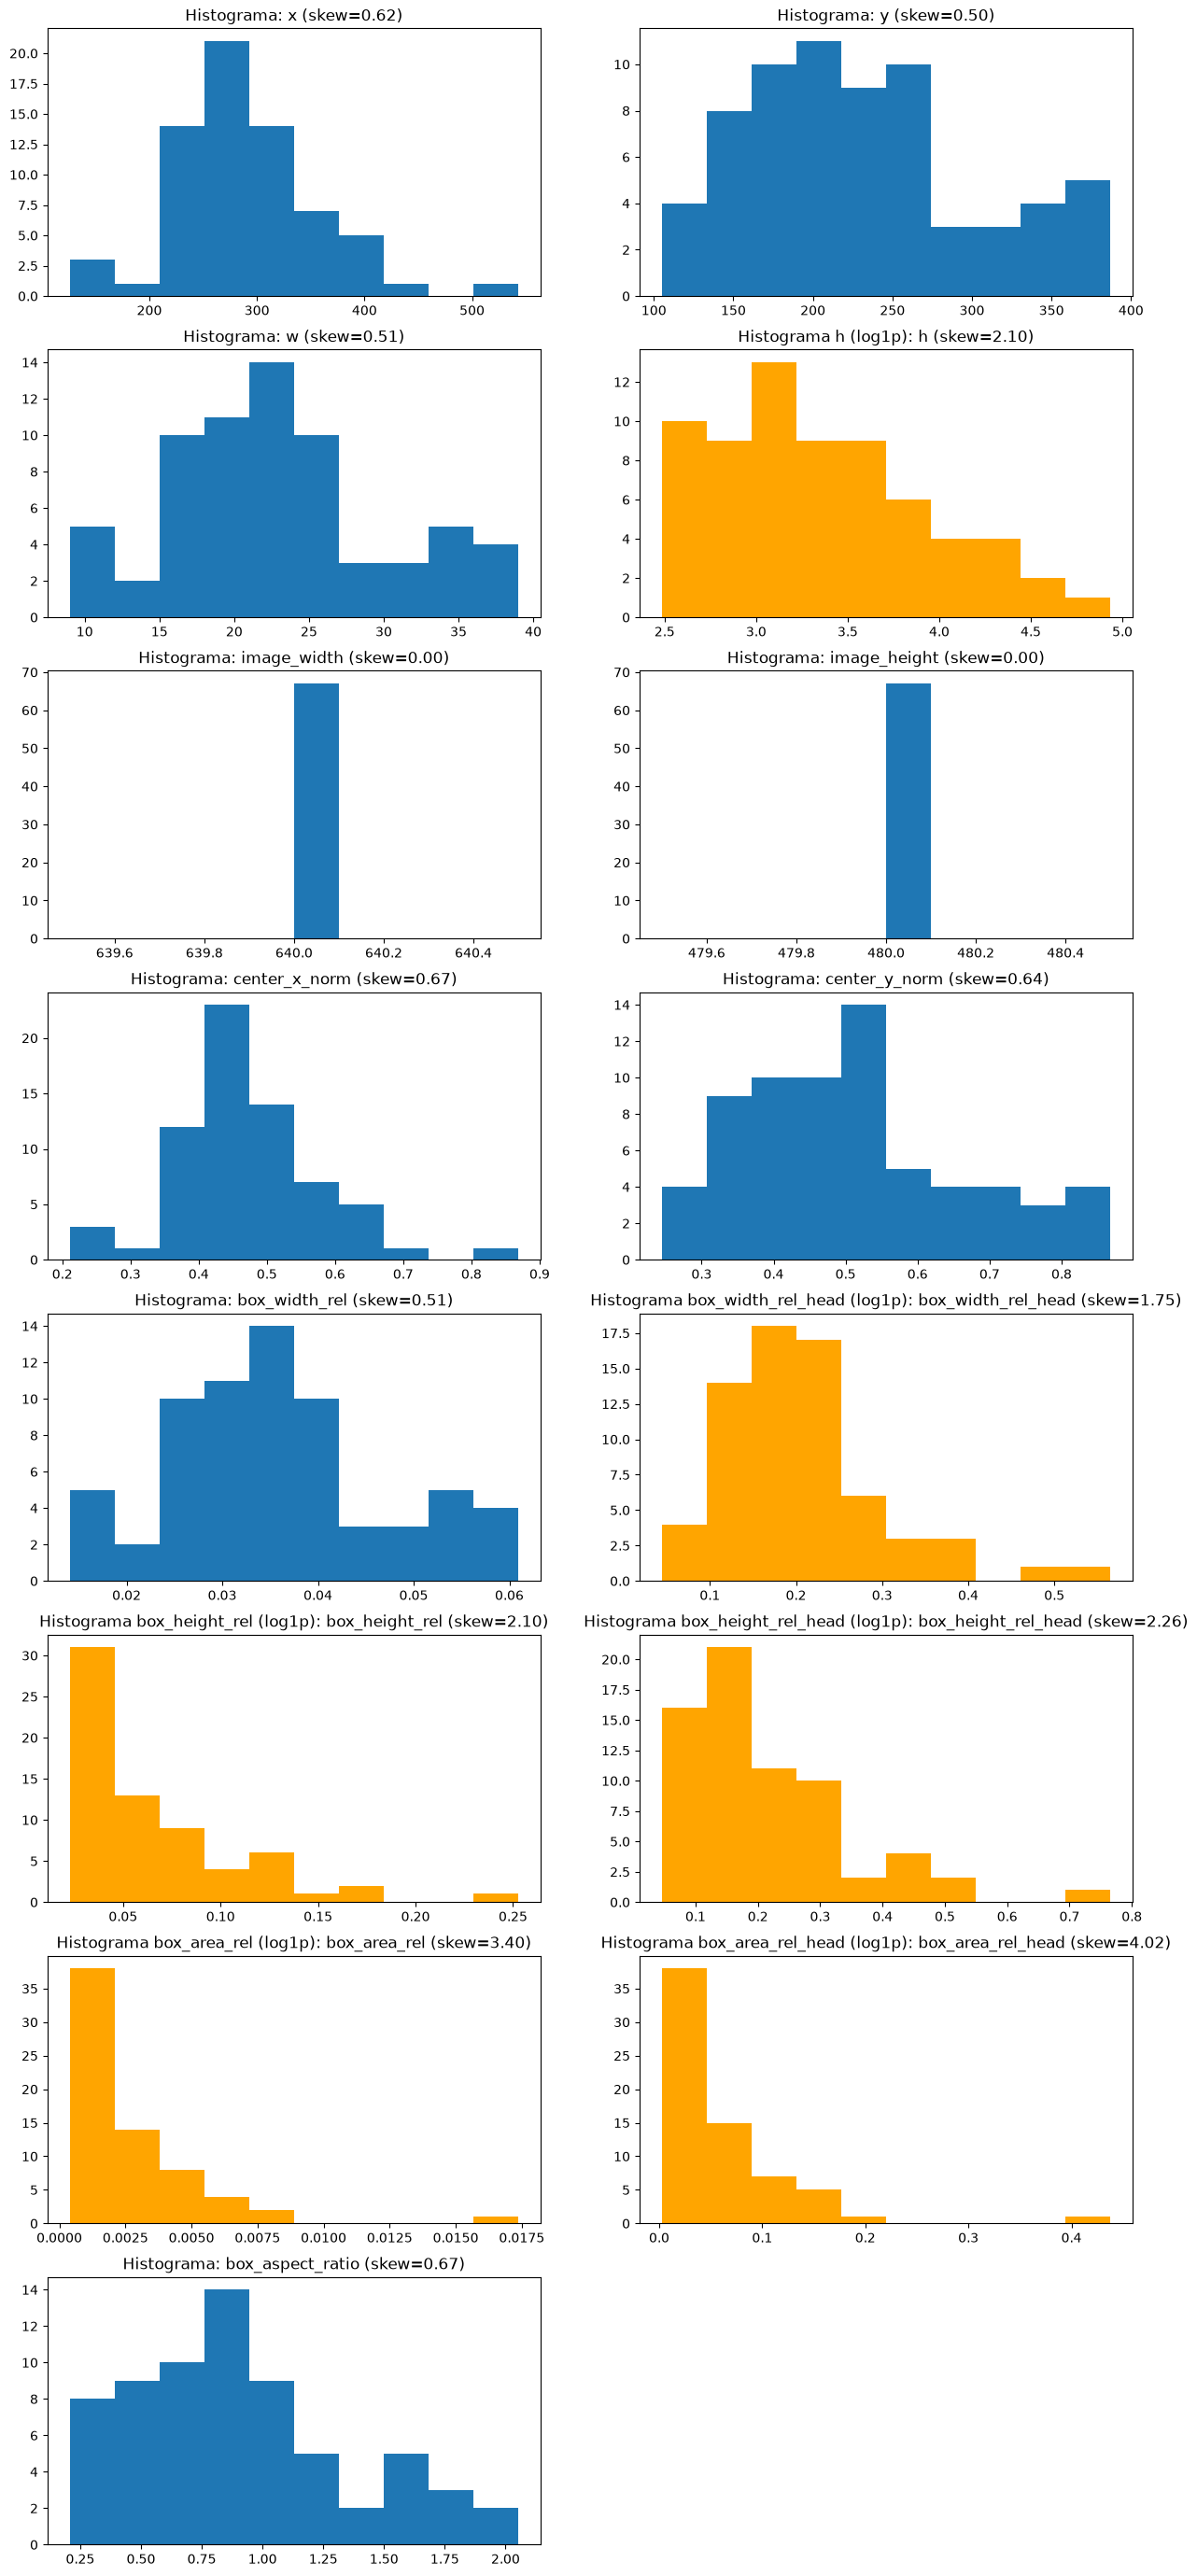

In [99]:
# Usar transformaciones (log1p) a aquellas con sesgo
# Se obtienen distribuciones o efectos a mejorar las caracteristicas de entrada.
features_df_norm=features_df.copy()
cols = features_df_norm.select_dtypes(include=[np.number]).columns
num_cols = len(cols)
n_rows = np.ceil(num_cols/2).astype(int)
plt.figure(figsize=(15,35))
i=0
for col in cols:
    i+=1
    skewness = features_df_norm[col].skew()
    if skewness > 1 or skewness < -1:
        features_df_norm[f"{col}_log1p"] = np.log1p(features_df_norm[col])
        plt.subplot(n_rows,2, i)
        plt.hist(features_df_norm[f"{col}_log1p"],color='orange')
        plt.title(f"Histograma {col} (log1p): {col} (skew={skewness:.2f})")
        features_df_norm.drop(columns=[col], inplace=True)
        #features_df_norm.columns = features_df_norm.columns.str.replace(col, f"{col}_log1p")
    else:
        plt.subplot(n_rows,2, i)
        plt.hist(features_df_norm[col])
        plt.title(f"Histograma: {col} (skew={skewness:.2f})")

### Normalización / escalamiento unitario
Dado el sesgo a la derecha observado en variables como (box_area_rel), se aplica transformación logarítmica (log1p) para normalizar la distribución en aquellas cuyo skewness esté fuera del rango -1 a 1.

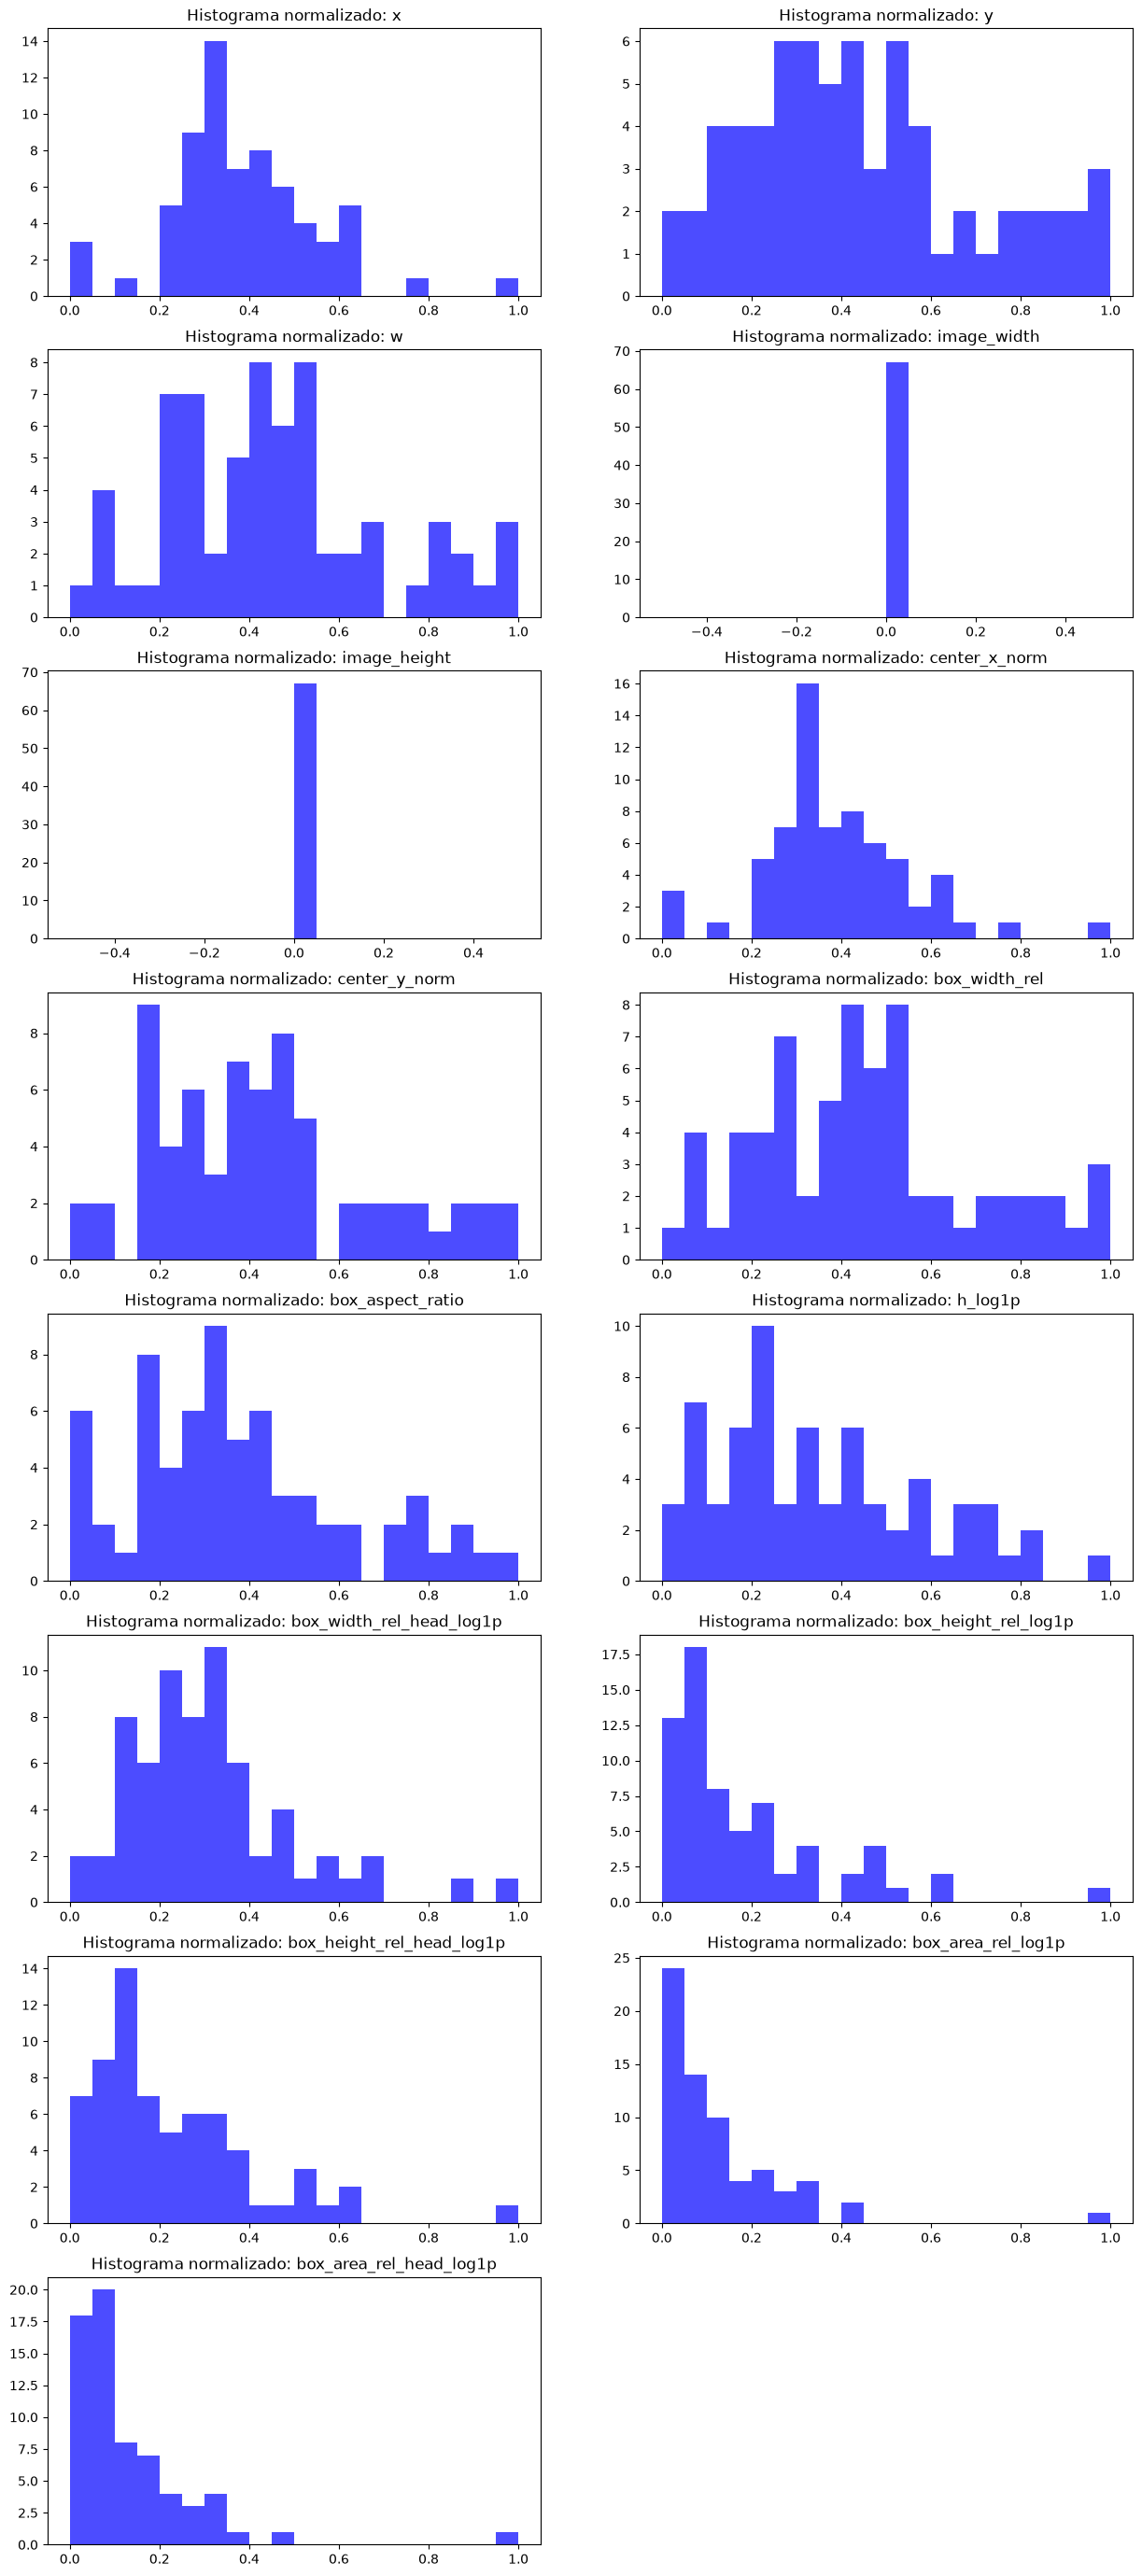

In [100]:

numeric_cols = features_df_norm.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    min_val = features_df_norm[col].min()
    max_val = features_df_norm[col].max()
    if max_val - min_val > 0:
        features_df_norm[col] = (features_df_norm[col] - min_val) / (max_val - min_val)
    else:
        features_df_norm[col] = 0.0  # Si todos los valores son iguales, asignar 0.0

cols = features_df_norm.select_dtypes(include=[np.number]).columns
num_cols = len(cols)
n_rows = np.ceil(num_cols/2).astype(int)
plt.figure(figsize=(15,35))
i=0
for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows,2, i + 1)
    plt.hist(features_df_norm[col], bins=20, color='blue', alpha=0.7)
    plt.title(f"Histograma normalizado: {col}")

In [101]:
features_df

,imagen,x,y,w,h,image_width,image_height,center_x_norm,center_y_norm,box_width_rel,box_width_rel_head,box_height_rel,box_height_rel_head,box_area_rel,box_area_rel_head,box_aspect_ratio
0,captura_20261003_153016_534962.jpg,219.0,387.0,39.0,59.0,640,480,0.372656,0.867708,0.060937,0.229412,0.122917,0.225191,0.007490,0.051661,0.661017
1,captura_20261003_153021_540685.jpg,396.0,382.0,37.0,52.0,640,480,0.647656,0.850000,0.057813,0.350711,0.108333,0.383764,0.006263,0.134590,0.711538
2,captura_20261003_153051_624221.jpg,259.0,203.0,11.0,14.0,640,480,0.413281,0.437500,0.017188,0.105263,0.029167,0.155556,0.000501,0.016374,0.785714
3,captura_20261003_153056_648946.jpg,294.0,300.0,11.0,11.0,640,480,0.467969,0.636458,0.017188,0.045175,0.022917,0.057592,0.000394,0.002602,1.000000
4,captura_20261003_153101_657504.jpg,244.0,217.0,15.0,13.0,640,480,0.392969,0.465625,0.023438,0.064240,0.027083,0.058427,0.000635,0.003753,1.153846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,captura_20261003_221712_761031.jpg,212.0,188.0,20.0,18.0,640,480,0.346875,0.410417,0.031250,0.211864,0.037500,0.138889,0.001172,0.029426,1.111111
63,captura_20261003_221712_761031.jpg,239.0,213.0,25.0,36.0,640,480,0.392969,0.481250,0.039062,0.264831,0.075000,0.277778,0.002930,0.073564,0.694444
64,captura_20261003_221712_761031.jpg,320.0,253.0,23.0,14.0,640,480,0.517969,0.541667,0.035937,0.243644,0.029167,0.108025,0.001048,0.026320,1.642857
65,captura_20261003_221717_781755.jpg,289.0,247.0,39.0,19.0,640,480,0.482031,0.534375,0.060937,0.477551,0.039583,0.158333,0.002412,0.075612,2.052632


array([[<Axes: title={'center': 'x'}>, <Axes: title={'center': 'y'}>,
        <Axes: title={'center': 'w'}>,
        <Axes: title={'center': 'center_x_norm'}>],
       [<Axes: title={'center': 'center_y_norm'}>,
        <Axes: title={'center': 'box_width_rel'}>,
        <Axes: title={'center': 'box_aspect_ratio'}>,
        <Axes: title={'center': 'h_log1p'}>],
       [<Axes: title={'center': 'box_width_rel_head_log1p'}>,
        <Axes: title={'center': 'box_height_rel_log1p'}>,
        <Axes: title={'center': 'box_height_rel_head_log1p'}>,
        <Axes: title={'center': 'box_area_rel_log1p'}>],
       [<Axes: title={'center': 'box_area_rel_head_log1p'}>, <Axes: >,
        <Axes: >, <Axes: >]], dtype=object)

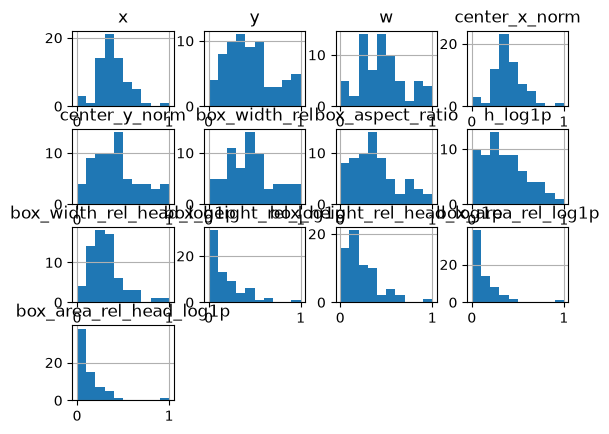

In [102]:
for col in numeric_cols:
    if features_df_norm[col].nunique() <= 1:
        features_df_norm.drop(columns=[col], inplace=True)

features_df_norm.hist()

## Codificación y Generación de características

Se extrae la hora de captura directamente del nombre de los archivos. A partir de esto, se crea una variable categórica para indicar el turno (Tarde o Noche) y se aplica One-Hot Encoding para su uso en los modelos.

In [103]:
# Sacamos la hora del nombre (ej. captura_20261003_153016 -> 15)
features_df_norm["hora"] = features_df_norm["imagen"].str.extract(r"_(\d{2})\d{4}_").astype(int)

# Lo dividimos en tarde y noche
features_df_norm["turno"] = pd.cut(features_df_norm["hora"], bins=[0, 18, 24], labels=["Tarde", "Noche"], right=False)

# Aplicamos One-Hot Encoding
features_df_norm = pd.get_dummies(features_df_norm, columns=["turno"])
features_df_norm.head()

,imagen,x,y,w,center_x_norm,center_y_norm,box_width_rel,box_aspect_ratio,h_log1p,box_width_rel_head_log1p,box_height_rel_log1p,box_height_rel_head_log1p,box_area_rel_log1p,box_area_rel_head_log1p,hora,turno_Tarde,turno_Noche
0,captura_20261003_153016_534962.jpg,0.223022,1.000000,1.000000,0.245843,1.000000,1.000000,0.246038,0.657029,0.311710,0.405450,0.218482,0.416431,0.109790,15,True,False
1,captura_20261003_153021_540685.jpg,0.647482,0.982270,0.933333,0.663895,0.971572,0.933333,0.273410,0.606387,0.492370,0.348626,0.387621,0.344626,0.284221,15,True,False
2,captura_20261003_153051_624221.jpg,0.318945,0.347518,0.066667,0.307601,0.309365,0.066667,0.313597,0.091095,0.107325,0.026479,0.137164,0.006326,0.031355,15,True,False
3,captura_20261003_153056_648946.jpg,0.402878,0.691489,0.066667,0.390736,0.628763,0.066667,0.429695,0.000000,0.000000,0.000000,0.014056,0.000000,0.000000,15,True,False
4,captura_20261003_153101_657504.jpg,0.282974,0.397163,0.200000,0.276722,0.354515,0.200000,0.513047,0.062930,0.034707,0.017671,0.015153,0.014184,0.002638,15,True,False


Se descartan variables sin variación

## Discretización (Binning)

Sediscretiza el área relativa de los objetos en tres categorías (Pequeño, Mediano y Grande) utilizando cuartiles, facilitando el procesamiento para algoritmos basados en reglas o árboles.

In [104]:
# Uso qcut para que queden balanceados los 3 grupos (se hizo log1p a box_area_rel previamente por skewness)
features_df_norm["categoria_tamano"] = pd.qcut(features_df_norm["box_area_rel_log1p"], q=3, labels=["Pequeno", "Mediano", "Grande"])

# Codificamos a números (0, 1, 2)
features_df_norm["tamano_codificado"] = features_df_norm["categoria_tamano"].cat.codes
features_df_norm[["box_area_rel_log1p", "categoria_tamano", "tamano_codificado"]].head()

,box_area_rel_log1p,categoria_tamano,tamano_codificado
0,0.416431,Grande,2
1,0.344626,Grande,2
2,0.006326,Pequeno,0
3,0.000000,Pequeno,0
4,0.014184,Pequeno,0


## Selección de características

Se evalúa la varianza y la correlación de las variables generadas para descartar redundancias.

Variables que pasaron el filtro de varianza: ['x', 'y', 'w', 'center_x_norm', 'center_y_norm', 'box_width_rel', 'box_aspect_ratio', 'h_log1p', 'box_width_rel_head_log1p', 'box_height_rel_log1p', 'box_height_rel_head_log1p', 'box_area_rel_log1p', 'box_area_rel_head_log1p', 'hora', 'tamano_codificado']


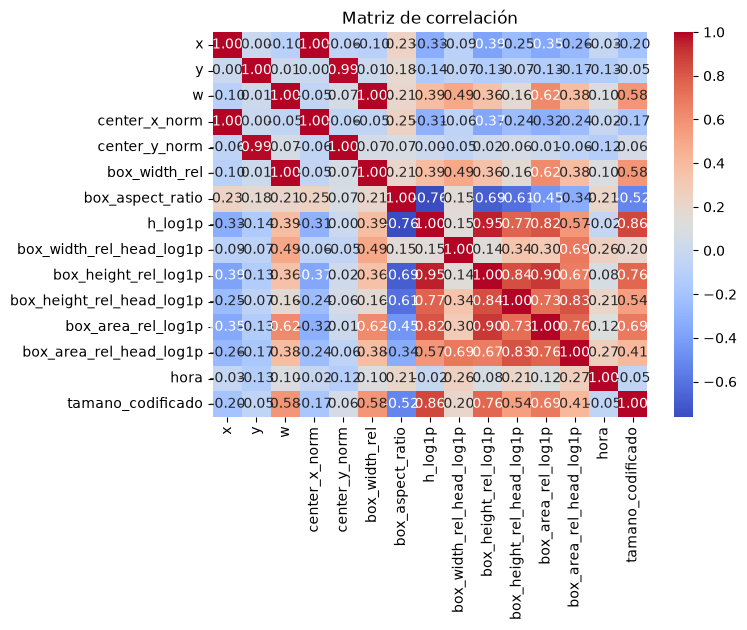

In [105]:
from sklearn.feature_selection import VarianceThreshold
import seaborn as sns

# 1. Filtro de varianza
num_cols = features_df_norm.select_dtypes(include=[np.number]).columns
selector = VarianceThreshold(threshold=0.01)
selector.fit(features_df_norm[num_cols])
print("Variables que pasaron el filtro de varianza:", features_df_norm[num_cols].columns[selector.get_support()].tolist())

# 2. Correlación
corr = features_df_norm[num_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

Al observar el mapa de calor, se identifica una alta correlación entre las proporciones (ancho/alto) y el área logarítmica, lo que justifica aplicar técnicas de reducción de dimensionalidad.

## Extracción de características (PCA)

Se aplica el Análisis de Componentes Principales (PCA) para reducir la dimensionalidad de las proporciones y tamaños, consolidando la información en dos componentes principales.

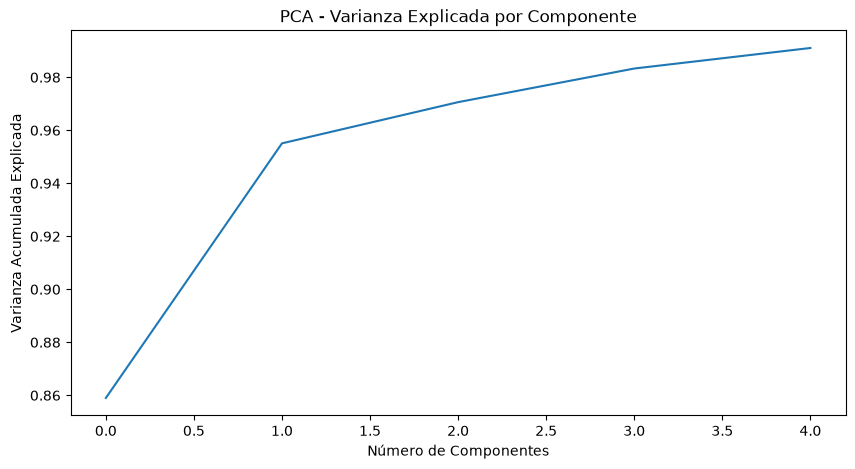

In [106]:
#Se aplica PCA para reducir la dimensionalidad y seleccionar las características más importantes.
from sklearn.decomposition import PCA

num_cols = features_df_norm.select_dtypes(include=[np.number]).columns
pca = PCA(n_components=0.99)  # Mantener el 99% de la varianza

features_df_pca = pca.fit_transform(features_df_norm[num_cols].dropna())

plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada Explicada')
plt.title('PCA - Varianza Explicada por Componente')
plt.show()

## Convoluciones
Puesto que las imagenes a utilizar serán procesadas por una red neural convolucional, es preciso mencionar que la extracción de características provendría tambien desde la sintonizacion de la red misma

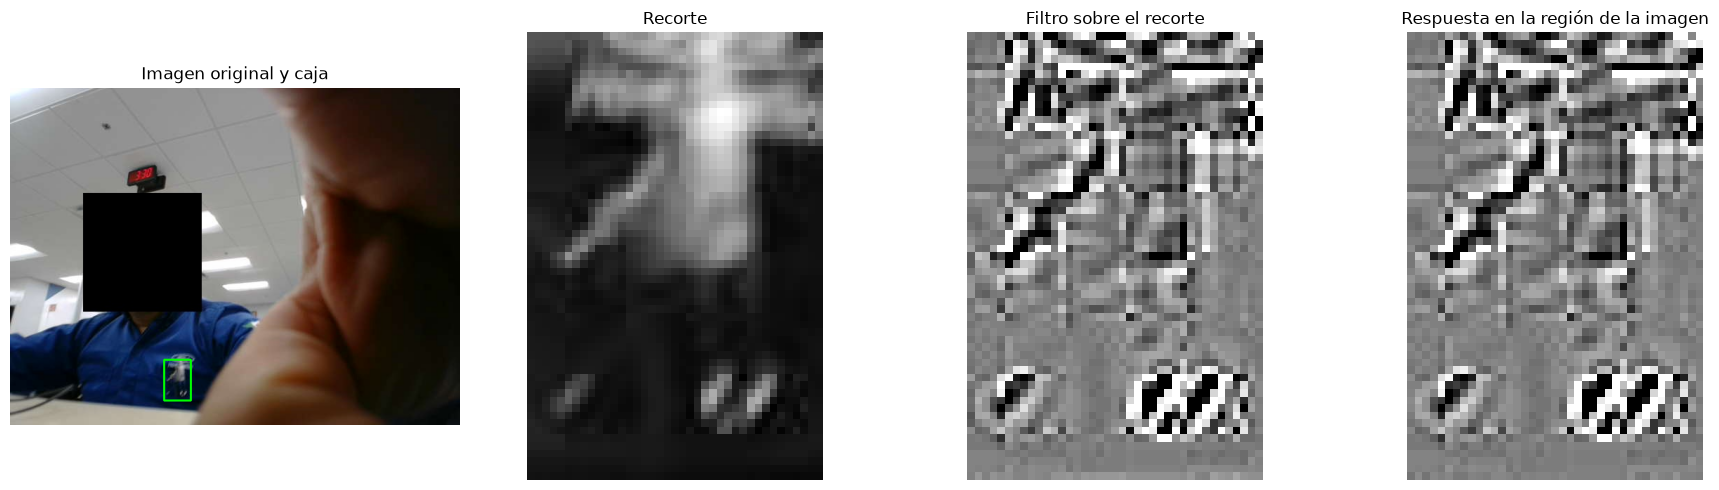

In [107]:
# Cambia estas rutas y coordenadas por un ejemplo real.
imagen_prueba="captura_20261003_153016_534962.jpg"
crop_prueba=imagen_prueba.replace('.jpg', '_001.jpg')
SOURCE_PATH =Path("../DataCapture/raw/captura_20261003_153016_534962.jpg")
CROP_PATH = Path("../DataCapture/NG/captura_20261003_153016_534962_001.jpg")

# Coordenadas de ESA caja en la imagen original, tomadas del CSV.
x, y, w, h = features_df[features_df["imagen"]==imagen_prueba][["x","y","w","h"]].iloc[0]

source = cv2.imread(SOURCE_PATH)
crop = cv2.imread(str(CROP_PATH))

if source is None:
    raise FileNotFoundError(f"No se pudo leer la imagen original: {SOURCE_PATH.name}")
if crop is None:
    raise FileNotFoundError(f"No se pudo leer el recorte: {CROP_PATH.name}")

# Validar y limitar la caja a los bordes de la imagen.
image_h, image_w = source.shape[:2]
x1 = max(0, int(x))
y1 = max(0, int(y))
x2 = min(image_w, int(x + w))
y2 = min(image_h, int(y + h))

if x2 <= x1 or y2 <= y1:
    raise ValueError("La caja no cae dentro de los límites de la imagen.")

# El recorte de referencia se obtiene de la imagen original usando la caja.
source_crop = source[y1:y2, x1:x2]

# A escala de grises, para que ambos filtros trabajen sobre el mismo canal.
source_gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
crop_gray = cv2.cvtColor(source_crop, cv2.COLOR_BGR2GRAY)

# Kernel fijo: resalta cambios de intensidad locales.
kernel = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0],
], dtype=np.float32)

# La misma operación y kernel para el recorte y la imagen completa.
response_crop = cv2.filter2D(
    crop_gray, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT101
)
response_full = cv2.filter2D(
    source_gray, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT101
)

# Extraer de la respuesta completa la región que corresponde a la caja.
response_full_roi = response_full[y1:y2, x1:x2]

# Usar el mismo rango de visualización para comparar respuestas.
limit = np.percentile(
    np.abs(np.concatenate([
        response_crop.ravel(),
        response_full.ravel()
    ])),
    99
)
limit = max(float(limit), 1e-6)

# Dibujar la caja en una copia de la imagen original.
source_display = source.copy()
cv2.rectangle(source_display, (x1, y1), (x2 - 1, y2 - 1), (0, 255, 0), 2)
source_display = cv2.cvtColor(source_display, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(source_display)
axes[0].set_title("Imagen original y caja")
axes[1].imshow(crop_gray, cmap="gray")
axes[1].set_title("Recorte")
axes[2].imshow(response_crop, cmap="gray", vmin=-limit, vmax=limit)
axes[2].set_title("Filtro sobre el recorte")
axes[3].imshow(response_full_roi, cmap="gray", vmin=-limit, vmax=limit)
axes[3].set_title("Respuesta en la región de la imagen")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Conclusiones (Fase de Preparación de datos según CRISP-ML)

En esta etapa se transformaron los datos crudos en un conjunto estructurado y listo para el modelado. Las acciones principales incluyen:
- Extracción y codificación temporal (turnos).
- Transformaciones logarítmicas para mitigar el sesgo en tamaños de objetos.
- Estandarización de variables para facilitar la convergencia paramétrica.
- Reducción de ruido y colinealidad mediante PCA.

Haciendo uso de las imágenes presentes se pudo hacer un estudio de las características geométricas de los recortes que incumplen el estandar de vestimenta.  
Se hizo uso del conocimiento a priori para seleccionar regularizaciones de tales valores: _al tener los accesorios asociados a una persona, se hizo uso del recorte de la cabeza para justamente tener una noción geométrica del objeto relativo a su portador_  
El presente sistema presenta limitaciones ya que se ha enfocado únicamente en los recortes dentro de una imagen y su escalabilidad dependerá en gran medida de qué tan estandarizada se encuentre la captura.  Para efectos prácticos el ejercicio permitió llegar a una selección de variables útiles.
El dataset resultante cumple con los requerimientos de calidad para iniciar la experimentación y validación de modelos predictivos.